# StreamView Analytics

Análisis exploratorio con el mismo catálogo y reglas que los dashboards. Ejecutar en orden. Requiere las dependencias de `requirements.txt`.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise RuntimeError('Abra el cuaderno desde la carpeta del proyecto o desde notebooks/.')
sys.path.insert(0, str(ROOT))
from src.prep import load_clean, explode
from src import metrics as M
df = load_clean()
print(df.groupby('tipo').size())
print('Total de títulos únicos:', len(df))
assert not df.duplicated(['tipo', 'show_id']).any()


tipo
Película    16000
Serie       15991
dtype: int64
Total de títulos únicos: 31991


## Calidad y variables

El año de estreno es `anio` y el año de incorporación es `anio_incorporacion`. Se utiliza la clave compuesta tipo + show_id. Países y géneros pueden contener varias categorías por título.


In [2]:
print(df.isna().sum().sort_values(ascending=False))
print(M.rated_catalog(df).groupby('tipo').calificacion.mean())
print('Calificación con votos:', M.kpis_catalogo(df)['calificacion_media'])
print('Popularidad mediana:', df.popularidad.median())


roi_pct               28468
presupuesto           27199
ingresos              26381
tipo                      0
show_id                   0
titulo                    0
cast                      0
anio                      0
anio_incorporacion        0
director                  0
idioma                    0
genres                    0
country                   0
calificacion              0
popularidad               0
votos                     0
tiene_finanzas            0
votos_suficientes         0
dtype: int64
tipo
Película    6.310965
Serie       7.030595
Name: calificacion, dtype: float64


Calificación con votos: 6.634187021230028
Popularidad mediana: 22.071


## Estrenos por año

La distribución es casi uniforme. No permite afirmar crecimiento real del catálogo ni retención de usuarios.


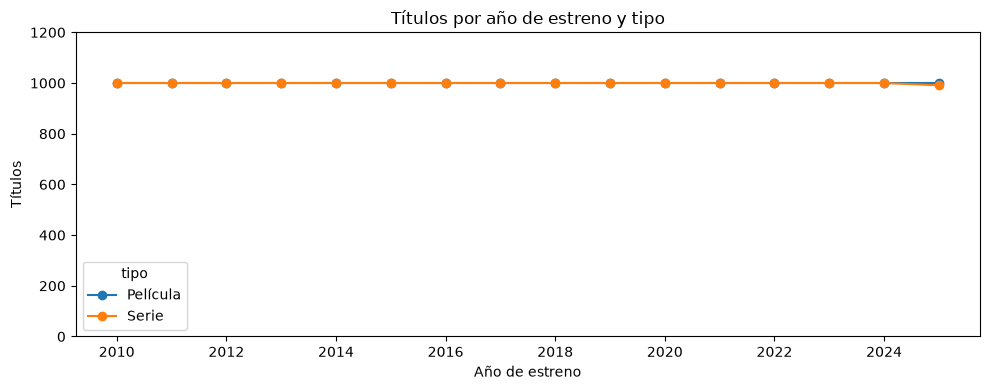

In [3]:
annual = M.por_anio(df).set_index('anio')
ax = annual.plot(marker='o', figsize=(10, 4))
ax.set_ylim(0, 1200)
ax.set_xlabel('Año de estreno')
ax.set_ylabel('Títulos')
ax.set_title('Títulos por año de estreno y tipo')
plt.tight_layout()
plt.show()


## Géneros y países

Un título se cuenta una sola vez dentro de cada categoría. Un título con varios países puede participar en más de una barra.


   genres  titulos
    Drama    14769
   Comedy     9105
Animation     4069
 Thriller     3769
   Action     3239
    Crime     3203
   Family     3014
  Mystery     2574
  Romance     2571
   Horror     2425
                 country  titulos
United States of America    10955
                   Japan     2869
          United Kingdom     2608
                   China     2399
             South Korea     2174
                  France     2108
                  Canada     1715
                 Germany     1160
                   India      912
                   Spain      822


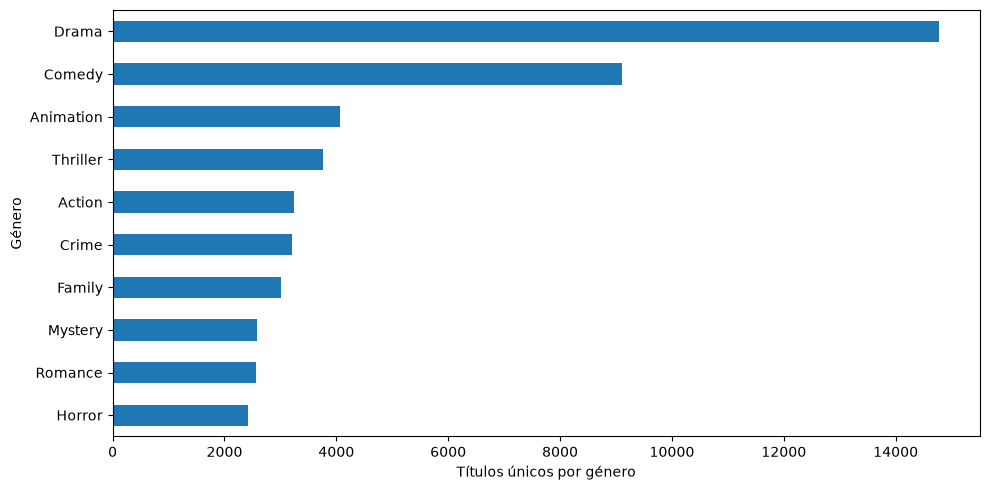

In [4]:
genres = M.top_generos(df)
countries = M.top_paises(df)
print(genres.to_string(index=False))
print(countries.to_string(index=False))
ax = genres.iloc[::-1].plot.barh(x='genres', y='titulos', legend=False, figsize=(10, 5))
ax.set_xlabel('Títulos únicos por género')
ax.set_ylabel('Género')
plt.tight_layout()
plt.show()


## Finanzas

Solo películas con presupuesto e ingresos de al menos USD 1.000 en ambos campos. Se utiliza la misma muestra en las sumas de presupuesto e ingresos. El ROI es aproximado y no representa el beneficio de la plataforma.


Películas con ambos datos: 3523
Cobertura sobre películas (%): 22.02
ROI agregado aproximado (%): 191.68


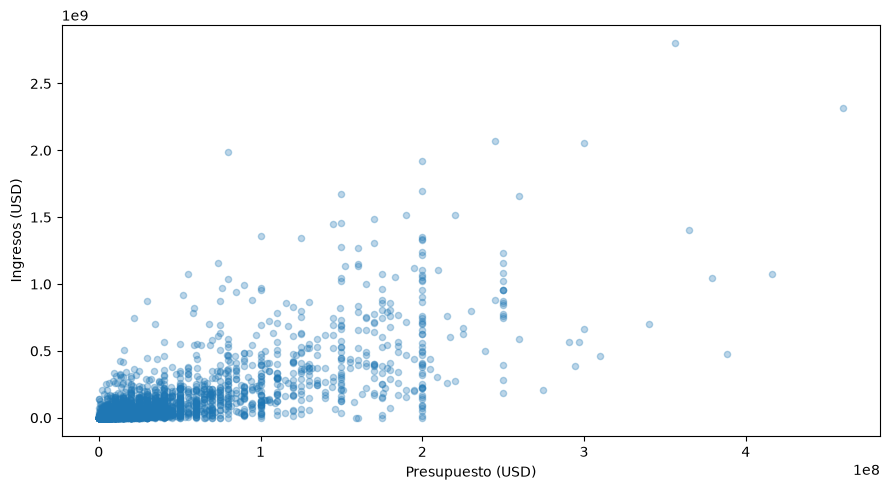

In [5]:
financial = M.kpis_financieros(df)
print('Películas con ambos datos:', financial['n'])
print('Cobertura sobre películas (%):', round(financial['cobertura_pct'], 2))
print('ROI agregado aproximado (%):', round(financial['roi_agregado_pct'], 2))
f = df[df.tiene_finanzas]
ax = f.plot.scatter(x='presupuesto', y='ingresos', alpha=0.3, figsize=(9, 5))
ax.set_xlabel('Presupuesto (USD)')
ax.set_ylabel('Ingresos (USD)')
plt.tight_layout()
plt.show()
assert len(f) == 3523


## Interpretación y decisiones
La calificación utiliza votos > 0 y nota > 0: media 6,63, n=27.414. La popularidad mediana es 22,07, frente a una media de 42,63.
Evaluar Animation y Documentary por sus valoraciones con votos suficientes. Explorar Corea del Sur y Japón, y realizar pilotos en Colombia o México. La elección final requiere consumo y costos de licencia.
Insidious y Get Out presentan ingresos superiores al presupuesto dentro de la muestra, pero el ROI no equivale al beneficio neto.
La correlación lineal popularidad-calificación es casi nula por tipo. La correlación de rangos es positiva débil (rho aproximado 0,24). No hay evidencia causal ni datos de demanda.
